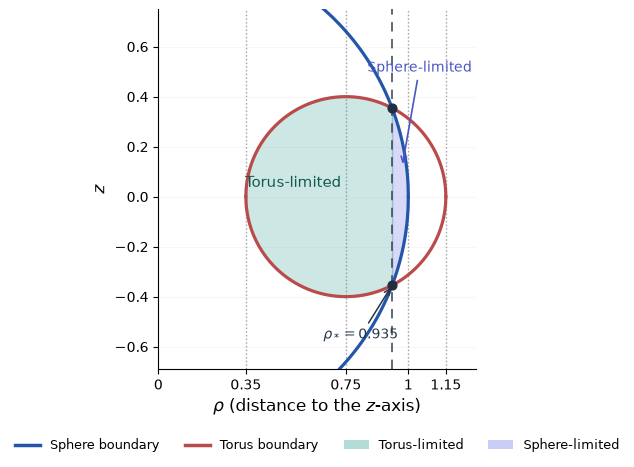

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

R, r, k = 0.75, 0.4, 1.0
rho_star = (k*k - r*r + R*R) / (2*R)
z_star = np.sqrt(k*k - rho_star*rho_star)

sphere_r = np.linspace(0, 1, 800)
sphere_z = np.sqrt(np.clip(1 - sphere_r**2, 0, None))

torus_r = np.linspace(R - r, R + r, 800)
torus_z = np.sqrt(np.clip(r**2 - (torus_r - R)**2, 0, None))

rt = np.linspace(R - r, rho_star, 500)
ht = np.sqrt(np.clip(r**2 - (rt - R)**2, 0, None))

rsp = np.linspace(rho_star, 1, 300)
hsp = np.sqrt(np.clip(k*k - rsp**2, 0, None))

fig, ax = plt.subplots(figsize=(8.8, 5.0))

ax.fill_between(rt, -ht, ht, color='#2a9d8f', alpha=0.24, zorder=1)
ax.fill_between(rsp, -hsp, hsp, color='#7b83e6', alpha=0.30, zorder=1)

ax.plot(sphere_r, sphere_z, color='#2356a8', lw=2.3, zorder=3)
ax.plot(sphere_r, -sphere_z, color='#2356a8', lw=2.3, zorder=3)

ax.plot(torus_r, torus_z, color='#ba4b4b', lw=2.3, zorder=3)
ax.plot(torus_r, -torus_z, color='#ba4b4b', lw=2.3, zorder=3)

for x in [R - r, R, 1.0, R + r]:
    ax.axvline(x, color='#555555', linestyle=':', lw=1.0, alpha=0.55, zorder=0)

ax.axvline(rho_star, color='#3c4653', linestyle=(0, (5, 4)), lw=1.35, alpha=0.85, zorder=2)
ax.scatter([rho_star, rho_star], [z_star, -z_star], s=40, color='#232e41', zorder=5)

ax.annotate(r'$\rho_*=0.935$',
            xy=(rho_star, -z_star),
            xytext=(0.66, -0.57),
            arrowprops=dict(arrowstyle='->', color='#263547', lw=1.1),
            fontsize=10, color='#263547')

ax.text(0.54, 0.055, 'Torus-limited',
        fontsize=11, ha='center', va='center', color='#14594d')

ax.annotate('Sphere-limited',
            xy=(0.975, 0.12),
            xytext=(1.045, 0.50),
            arrowprops=dict(arrowstyle='->', color='#4b55c3', lw=1.2),
            fontsize=10, color='#4b55c3', ha='center')

ax.set_xlim(0, 1.27)
ax.set_ylim(-0.69, 0.75)
ax.set_aspect('equal', adjustable='box')

ax.set_xlabel(r'$\rho$ (distance to the $z$-axis)', fontsize=12)
ax.set_ylabel(r'$z$', fontsize=12)

ax.grid(alpha=0.12, lw=0.6)
ax.spines[['top', 'right']].set_visible(False)

ax.set_xticks([0, 0.35, 0.75, 1.0, 1.15])
ax.set_xticklabels(['0', '0.35', '0.75', '1', '1.15'])

handles = [
    Line2D([0], [0], color='#2356a8', lw=2.5, label='Sphere boundary'),
    Line2D([0], [0], color='#ba4b4b', lw=2.5, label='Torus boundary'),
    Patch(facecolor='#2a9d8f', alpha=0.35, edgecolor='none', label='Torus-limited'),
    Patch(facecolor='#7b83e6', alpha=0.40, edgecolor='none', label='Sphere-limited')
]

ax.legend(handles=handles, loc='upper center', fontsize=9,
          frameon=False, ncol=4, bbox_to_anchor=(0.5, -0.16))

fig.subplots_adjust(left=0.10, right=0.98, top=0.96, bottom=0.24)

plt.show()


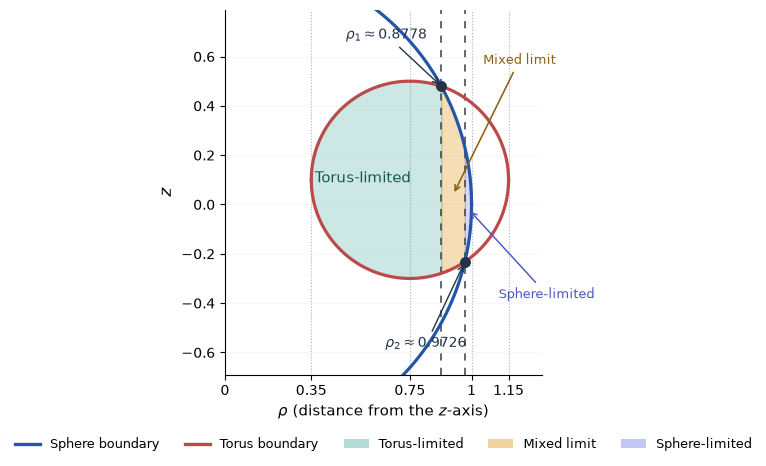

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

R, r, dz = 0.75, 0.4, 0.1

# Intersections of:
# rho^2 + z^2 = 1
# (rho - R)^2 + (z - dz)^2 = r^2
coeff = [
    1 + (R / dz)**2,
    -(R / dz**2) * (1 + R*R + dz*dz - r*r),
    ((1 + R*R + dz*dz - r*r) / (2 * dz))**2 - 1
]
roots = np.sort(np.roots(coeff).real)
rho1, rho2 = roots

zs = lambda rho: np.sqrt(np.clip(1 - rho*rho, 0, None))
zt = lambda rho: np.sqrt(np.clip(r*r - (rho - R)**2, 0, None))

rs = np.linspace(0, 1, 1000)
rt = np.linspace(R - r, R + r, 1000)

fig, ax = plt.subplots(figsize=(8.8, 5.0))

for xlo, xhi, color, alpha in [
    (0.35, rho1, '#2a9d8f', 0.24),
    (rho1, rho2, '#e7aa41', 0.38),
    (rho2, 1.0, '#7b83e6', 0.30)
]:
    xx = np.linspace(xlo, xhi, 600)
    top = np.minimum(zs(xx), dz + zt(xx))
    bot = np.maximum(-zs(xx), dz - zt(xx))
    ax.fill_between(xx, bot, top, color=color, alpha=alpha, zorder=1)

ax.plot(rs, zs(rs), color='#2356a8', lw=2.3, zorder=3)
ax.plot(rs, -zs(rs), color='#2356a8', lw=2.3, zorder=3)

ax.plot(rt, dz + zt(rt), color='#ba4b4b', lw=2.3, zorder=3)
ax.plot(rt, dz - zt(rt), color='#ba4b4b', lw=2.3, zorder=3)

for v in [R - r, R, 1, R + r]:
    ax.axvline(v, color='#737373', lw=0.8, ls=':', alpha=0.5, zorder=0)

for v in [rho1, rho2]:
    ax.axvline(v, color='#324052', lw=1.3, ls=(0, (4, 4)), alpha=0.85, zorder=2)

ax.scatter([rho1, rho2], [zs(rho1), -zs(rho2)], color='#263346', s=47, zorder=5)

ax.annotate(r'$\rho_1\approx0.8778$',
            xy=(rho1, zs(rho1)),
            xytext=(0.49, 0.67),
            arrowprops=dict(arrowstyle='->', color='#243347', lw=1),
            fontsize=10, color='#243347')

ax.annotate(r'$\rho_2\approx0.9726$',
            xy=(rho2, -zs(rho2)),
            xytext=(0.65, -0.58),
            arrowprops=dict(arrowstyle='->', color='#243347', lw=1),
            fontsize=10, color='#243347')

ax.text(0.56, 0.09, 'Torus-limited',
        fontsize=10.5, color='#14594d', ha='center')

ax.annotate('Mixed limit',
            xy=((rho1 + rho2) / 2, 0.04),
            xytext=(1.047, 0.57),
            arrowprops=dict(arrowstyle='->', color='#8b6115', lw=1.15),
            fontsize=9.5, color='#8b6115', ha='left')

ax.annotate('Sphere-limited',
            xy=(0.988, -0.02),
            xytext=(1.11, -0.38),
            arrowprops=dict(arrowstyle='->', color='#4b55c3', lw=1.05),
            fontsize=9.5, color='#4b55c3', ha='left')

ax.set_xlim(0, 1.285)
ax.set_ylim(-0.69, 0.79)
ax.set_aspect('equal', adjustable='box')

ax.set_xticks([0, 0.35, 0.75, 1, 1.15])
ax.set_xticklabels(['0', '0.35', '0.75', '1', '1.15'])

ax.set_xlabel(r'$\rho$ (distance from the $z$-axis)', fontsize=11)
ax.set_ylabel(r'$z$', fontsize=12)

ax.grid(alpha=0.11, lw=0.6)
ax.spines[['top', 'right']].set_visible(False)

handles = [
    Line2D([0], [0], color='#2356a8', lw=2.4, label='Sphere boundary'),
    Line2D([0], [0], color='#ba4b4b', lw=2.4, label='Torus boundary'),
    Patch(facecolor='#2a9d8f', alpha=0.35, label='Torus-limited'),
    Patch(facecolor='#e7aa41', alpha=0.50, label='Mixed limit'),
    Patch(facecolor='#7b83e6', alpha=0.45, label='Sphere-limited')
]

ax.legend(handles=handles, loc='upper center', ncol=5,
          frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.14))

fig.subplots_adjust(top=0.96, bottom=0.23, left=0.10, right=0.98)

plt.show()
